# Tap Water Quality Monitoring in the MWA Distribution Network (Jan–Aug 2026)
# การวิเคราะห์คุณภาพน้ำประปาในโครงข่ายท่อจ่ายน้ำของการประปานครหลวง (ม.ค.–ส.ค. 2569)

**Environmental Machine Learning Project — Project 1 (Group)**

**Environmental problem / ปัญหาสิ่งแวดล้อม**

Free residual chlorine is the last barrier against microbial regrowth in a drinking-water network. The MWA keeps it at **≥ 0.2 mg/L** at the tap, while turbidity and pH must stay within drinking-water criteria. Chlorine decays as water travels through pipes, and rainy-season raw water carries more suspended solids — so water that leaves the plant safe may not arrive safe everywhere.

คลอรีนอิสระคงเหลือเป็นด่านสุดท้ายที่ป้องกันเชื้อโรคในระบบท่อ กปน. ควบคุมให้ไม่ต่ำกว่า **0.2 mg/L** ส่วนความขุ่นและ pH ต้องอยู่ในเกณฑ์น้ำบริโภค แต่คลอรีนจะสลายตัวระหว่างที่น้ำเดินทางในท่อ และน้ำดิบช่วงฤดูฝนมีตะกอนมากขึ้น น้ำที่ออกจากโรงงานผลิตได้มาตรฐานจึงอาจไม่ได้มาตรฐานเท่ากันทุกจุดที่ปลายทาง

**Questions / คำถามที่ต้องการตอบ**
1. Does tap water at the three selected stations meet the chlorine, turbidity and pH criteria? / น้ำประปาที่ 3 สถานีผ่านเกณฑ์หรือไม่
2. How do the stations differ, and does the rainy season change turbidity and chlorine? / แต่ละสถานีต่างกันอย่างไร และฤดูฝนทำให้ความขุ่นและคลอรีนเปลี่ยนไปหรือไม่
3. How are the parameters related? / พารามิเตอร์สัมพันธ์กันอย่างไร
4. Can a simple ML model forecast next-hour chlorine as an early-warning tool? / โมเดล ML อย่างง่ายทำนายคลอรีนชั่วโมงถัดไปเพื่อเตือนล่วงหน้าได้หรือไม่

## 0. Setup / เตรียมเครื่องมือ

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")

DATA = Path("../data")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
(DATA / "processed").mkdir(exist_ok=True)

STATIONS = ["S001", "S017", "S021"]
STATION_LABEL = {
    "S001": "S001 School",
    "S017": "S017 Dialysis centre",
    "S021": "S021 Industrial estate",
}
PALETTE = {"S001": "#2a78b5", "S017": "#d9822b", "S021": "#3a9a5b"}
START, END = "2026-01-01", "2026-08-31 23:00"

# Drinking-water criteria / เกณฑ์ที่ใช้
CL_MIN = 0.2          # mg/L  free residual chlorine (MWA / WHO)
TURB_MAX = 5.0        # NTU   Dept. of Health drinking-water criterion
TURB_TARGET = 1.0     # NTU   stricter internal target set by the group
PH_MIN, PH_MAX = 6.5, 8.5

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches="tight")

## 1. Dataset / ชุดข้อมูล

Hourly online water-quality data from MWA monitoring stations across Bangkok, Nonthaburi and Samut Prakan (`water_quality_online_2569`). Columns: station code and name, timestamp, turbidity (NTU), free residual chlorine (mg/L), pH, conductivity (µS/cm), salinity (ppt) and chloride (mg/L).

ข้อมูลคุณภาพน้ำออนไลน์รายชั่วโมงจากสถานีตรวจวัดของ กปน. ในกรุงเทพฯ นนทบุรี และสมุทรปราการ

In [2]:
raw = pd.read_csv(DATA / "water_quality_online_2569.csv.gz", parse_dates=["date_time"])
print(raw.shape)
print("Stations:", raw.station_code.nunique())
print("Period:", raw.date_time.min(), "→", raw.date_time.max())
raw.head()

(273895, 9)
Stations: 59
Period: 2026-01-01 00:00:00 → 2026-09-07 23:00:00


,station_code,station_name,date_time,turbidity,free_residual_chlorine,ph,conductivity,salinity,chloride
0,S001,โรงเรียนเตรียมอุดมศึกษาน้อมเกล้า นนทบุรี,2026-01-01,0.650,0.360,7.440,363,0.160,17.380
1,S002,โรงเรียนทหารขนส่ง กรมการขนส่งทหารบก,2026-01-01,0.380,1.270,7.210,356,0.160,15.160
2,S003,กองพันทหารสื่อสาร กองบัญชาการกองทัพไทย,2026-01-01,0.460,0.710,7.060,372,0.170,19.990
3,S004,โรงพยาบาลภูมิพลอดุลยเดช,2026-01-01,0.130,0.870,7.140,372,0.170,19.900
4,S005,โรงพยาบาลซีจีเอช สายไหม,2026-01-01,0.280,0.300,7.170,374,0.170,20.600


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 273895 entries, 0 to 273894
Data columns (total 9 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   station_code            273895 non-null  str           
 1   station_name            273895 non-null  str           
 2   date_time               273895 non-null  datetime64[us]
 3   turbidity               273895 non-null  float64       
 4   free_residual_chlorine  273895 non-null  float64       
 5   ph                      273895 non-null  float64       
 6   conductivity            273895 non-null  int64         
 7   salinity                273895 non-null  float64       
 8   chloride                273895 non-null  float64       
dtypes: datetime64[us](1), float64(5), int64(1), str(2)
memory usage: 18.8 MB


## 2. Data Cleaning and Transformation / การทำความสะอาดและแปลงข้อมูล

Steps / ขั้นตอน
1. Check data types and missing values / ตรวจชนิดข้อมูลและค่าว่าง
2. Remove duplicate rows / ลบข้อมูลซ้ำ
3. Flag physically impossible zeros / ตรวจค่าศูนย์ที่ผิดปกติ
4. Check chloride values stuck at 10 / ตรวจค่าคลอไรด์ที่ค้างที่ 10
5. Select the analysis period (1 Jan – 31 Aug 2026) and 3 stations / เลือกช่วงเวลาและสถานี
6. Measure completeness and gaps on a full hourly grid / ตรวจความครบถ้วนและช่วงข้อมูลขาด
7. Add time features (date, month, hour, season) / เพิ่มคอลัมน์เวลาและฤดู

In [4]:
# 2.1 Types & missing values
print(raw.dtypes)
print("\nMissing values per column:\n", raw.isna().sum())

station_code                         str
station_name                         str
date_time                 datetime64[us]
turbidity                        float64
free_residual_chlorine           float64
ph                               float64
conductivity                       int64
salinity                         float64
chloride                         float64
dtype: object

Missing values per column:
 station_code              0
station_name              0
date_time                 0
turbidity                 0
free_residual_chlorine    0
ph                        0
conductivity              0
salinity                  0
chloride                  0
dtype: int64


In [5]:
# 2.2 Duplicates
n_dup = raw.duplicated(["station_code", "date_time"]).sum()
df = raw.drop_duplicates(["station_code", "date_time"]).copy()
print(f"Duplicate station-hour rows removed: {n_dup:,}  →  {len(df):,} rows left")

Duplicate station-hour rows removed: 447  →  273,448 rows left


In [6]:
# 2.3 Zero values (a reading of exactly 0 is a sensor/communication fault, not real water)
params = ["turbidity", "free_residual_chlorine", "ph", "conductivity", "salinity", "chloride"]
zeros = (df[params] == 0).sum()
print("Exact-zero readings, all stations:\n", zeros[zeros > 0])
df[params] = df[params].mask(df[params] == 0)  # treat as missing

Exact-zero readings, all stations:
 turbidity                  13
free_residual_chlorine    102
dtype: int64


In [7]:
# 2.4 Chloride stuck at 10 mg/L
share_10 = (df.chloride == 10).mean()
print(f"Share of chloride readings equal to exactly 10: {share_10:.1%}")
df.chloride.value_counts().head()

Share of chloride readings equal to exactly 10: 86.0%


chloride
10.000    235096
17.280       562
16.670       548
16.980       544
17.880       510
Name: count, dtype: int64

Most chloride readings are exactly **10**, which looks like a reporting floor (values below the instrument's range are reported as 10). The true value is unknown, so **chloride is excluded** from the analysis.

ค่าคลอไรด์ส่วนใหญ่เท่ากับ **10** พอดี น่าจะเป็นค่าต่ำสุดที่ระบบรายงาน (ค่าจริงต่ำกว่านั้นแต่ไม่ทราบ) จึง **ตัดคลอไรด์ออก** จากการวิเคราะห์

In [8]:
# 2.5 Period & stations
df = df[(df.date_time >= START) & (df.date_time <= END) & df.station_code.isin(STATIONS)].copy()
names = df.drop_duplicates("station_code").set_index("station_code").station_name
print(names)
print("\nRows per station:\n", df.station_code.value_counts().sort_index())

station_code
S001    โรงเรียนเตรียมอุดมศึกษาน้อมเกล้า นนทบุรี
S017            ศูนย์ไตเทียมเทียนฟ้าประชาการุณย์
S021                        นิคมอุตสาหกรรมบางพลี
Name: station_name, dtype: str

Rows per station:
 station_code
S001    5458
S017    5704
S021    5707
Name: count, dtype: int64


In [9]:
# 2.6 Completeness on a full hourly grid
full_idx = pd.date_range(START, END, freq="h")
expected = len(full_idx)
rows = []
for s in STATIONS:
    t = df[df.station_code == s].set_index("date_time").reindex(full_idx)
    miss = t.turbidity.isna() & t.free_residual_chlorine.isna() & t.ph.isna()
    runs = (miss != miss.shift()).cumsum()[miss]
    gap_len = runs.value_counts()
    rows.append({
        "station": s,
        "hours_expected": expected,
        "hours_present": int((~miss).sum()),
        "completeness_%": 100 * (~miss).mean(),
        "n_gaps": len(gap_len),
        "longest_gap_h": int(gap_len.max()) if len(gap_len) else 0,
    })
completeness = pd.DataFrame(rows).set_index("station")
completeness

,hours_expected,hours_present,completeness_%,n_gaps,longest_gap_h
station,,,,,
S001,5832,5458,93.587,96,48
S017,5832,5704,97.805,43,23
S021,5832,5707,97.857,34,23


In [10]:
# 2.7 Time features & season (Thai dry season Jan–Apr, rainy season May–Aug)
df = df.drop(columns=["chloride", "station_name"])
df["date"] = df.date_time.dt.normalize()
df["month"] = df.date_time.dt.month
df["hour"] = df.date_time.dt.hour
df["season"] = np.where(df.month <= 4, "Dry (Jan–Apr)", "Rainy (May–Aug)")
df = df.sort_values(["station_code", "date_time"]).reset_index(drop=True)

df.to_csv(DATA / "processed" / "clean_3stations_2026-01_08.csv", index=False)
print(df.shape)
df.head()

(16869, 11)


,station_code,date_time,turbidity,free_residual_chlorine,ph,conductivity,salinity,date,month,hour,season
0,S001,2026-01-01 00:00:00,0.650,0.360,7.440,363,0.160,2026-01-01,1,0,Dry (Jan–Apr)
1,S001,2026-01-01 01:00:00,0.640,0.280,7.430,364,0.160,2026-01-01,1,1,Dry (Jan–Apr)
2,S001,2026-01-01 02:00:00,0.620,0.230,7.470,365,0.170,2026-01-01,1,2,Dry (Jan–Apr)
3,S001,2026-01-01 03:00:00,0.620,0.230,7.450,365,0.170,2026-01-01,1,3,Dry (Jan–Apr)
4,S001,2026-01-01 04:00:00,0.620,0.250,7.450,366,0.170,2026-01-01,1,4,Dry (Jan–Apr)


## 3. Exploratory Data Analysis (EDA) / การสำรวจข้อมูลเบื้องต้น

In [11]:
desc = (df.groupby("station_code")[["turbidity", "free_residual_chlorine", "ph", "conductivity"]]
          .agg(["count", "mean", "std", "min", "median", "max"]))
desc.T

station_code                      S001     S017     S021
turbidity              count  5458.000 5704.000 5707.000
                       mean      0.568    0.580    0.450
                       std       0.159    0.207    0.213
                       min       0.050    0.100    0.100
                       median    0.580    0.560    0.430
                       max       1.520    1.670    2.570
free_residual_chlorine count  5458.000 5704.000 5707.000
                       mean      0.544    0.962    0.867
                       std       0.174    0.205    0.190
                       min       0.130    0.250    0.110
                       median    0.540    0.960    0.870
                       max       1.280    1.650    1.400
ph                     count  5458.000 5704.000 5707.000
                       mean      7.388    7.287    7.235
                       std       0.103    0.073    0.108
                       min       7.000    6.830    6.890
                       median    7.400    7.290    7.250
                       max       7.670    7.500    7.420
conductivity           count  5458.000 5704.000 5707.000
                       mean    287.587  290.958  295.188
                       std      45.265   43.525   40.423
                       min     221.000  225.000  240.000
                       median  280.000  280.000  282.000
                       max     390.000  391.000  397.000

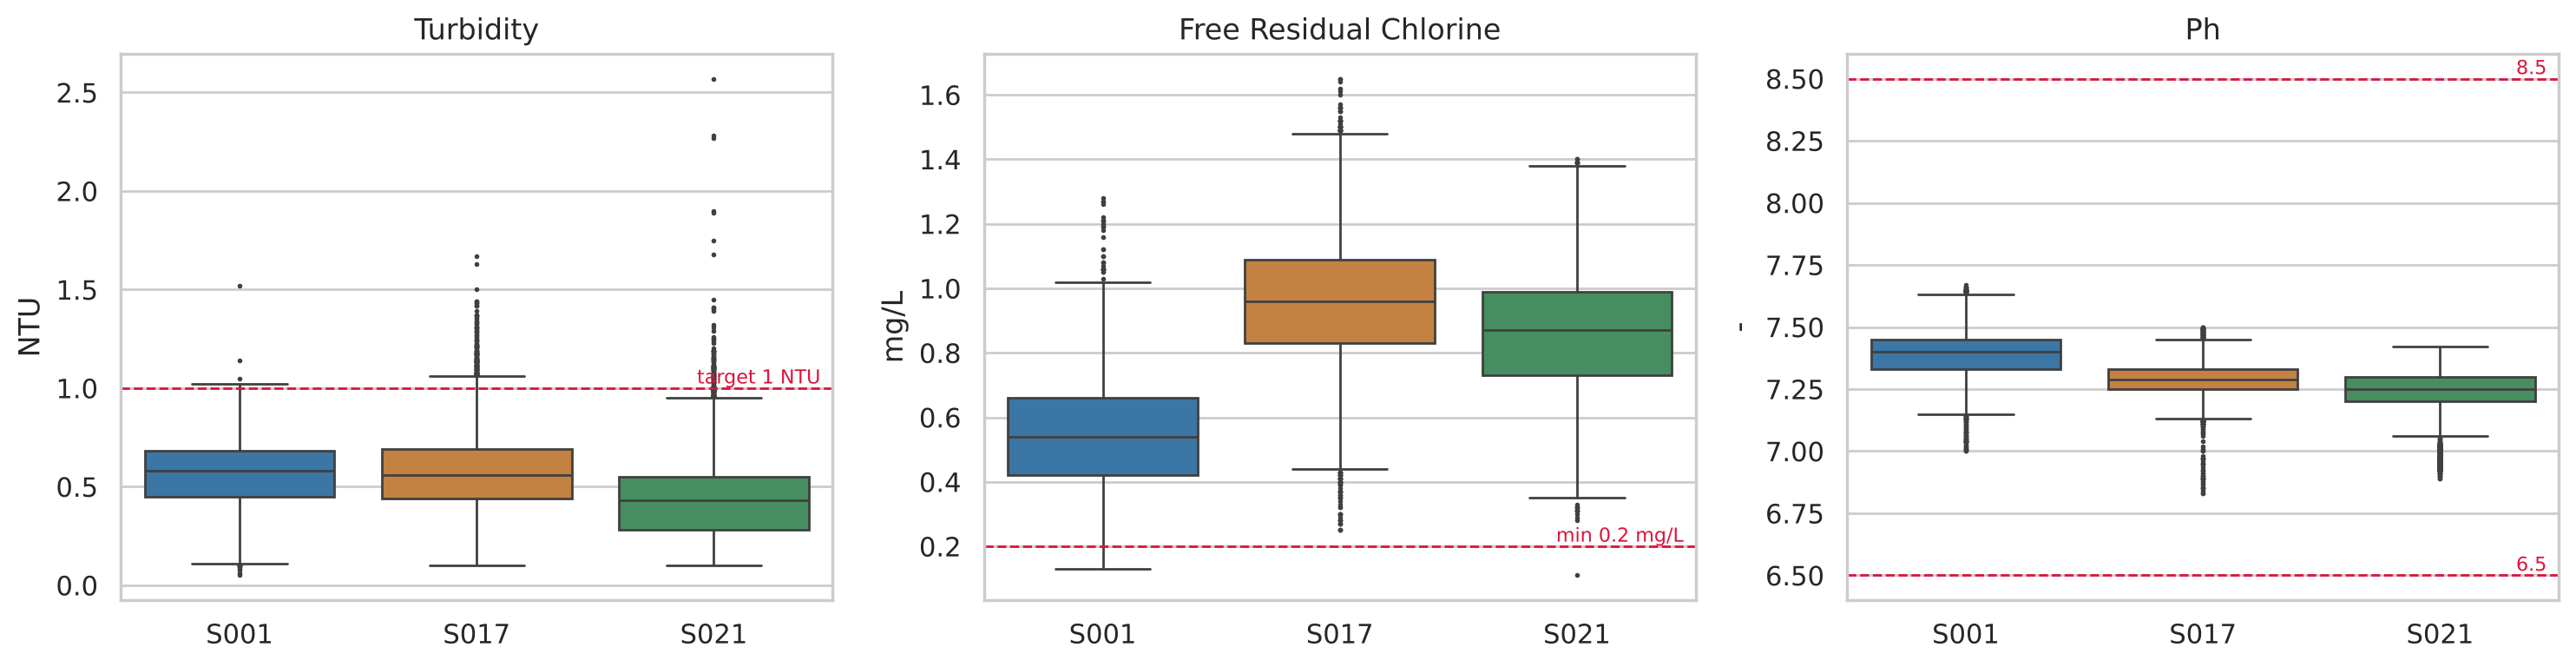

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, unit, lines) in zip(axes, [
        ("turbidity", "NTU", [(TURB_TARGET, "target 1 NTU")]),
        ("free_residual_chlorine", "mg/L", [(CL_MIN, "min 0.2 mg/L")]),
        ("ph", "-", [(PH_MIN, "6.5"), (PH_MAX, "8.5")])]):
    sns.boxplot(data=df, x="station_code", y=col, hue="station_code", palette=PALETTE,
                order=STATIONS, ax=ax, fliersize=1, legend=False)
    for v, lab in lines:
        ax.axhline(v, ls="--", c="crimson", lw=1)
        ax.text(2.45, v, lab, color="crimson", va="bottom", ha="right", fontsize=8)
    ax.set_title(col.replace("_", " ").title()); ax.set_xlabel(""); ax.set_ylabel(unit)
savefig("01_boxplot_by_station.png"); plt.show()

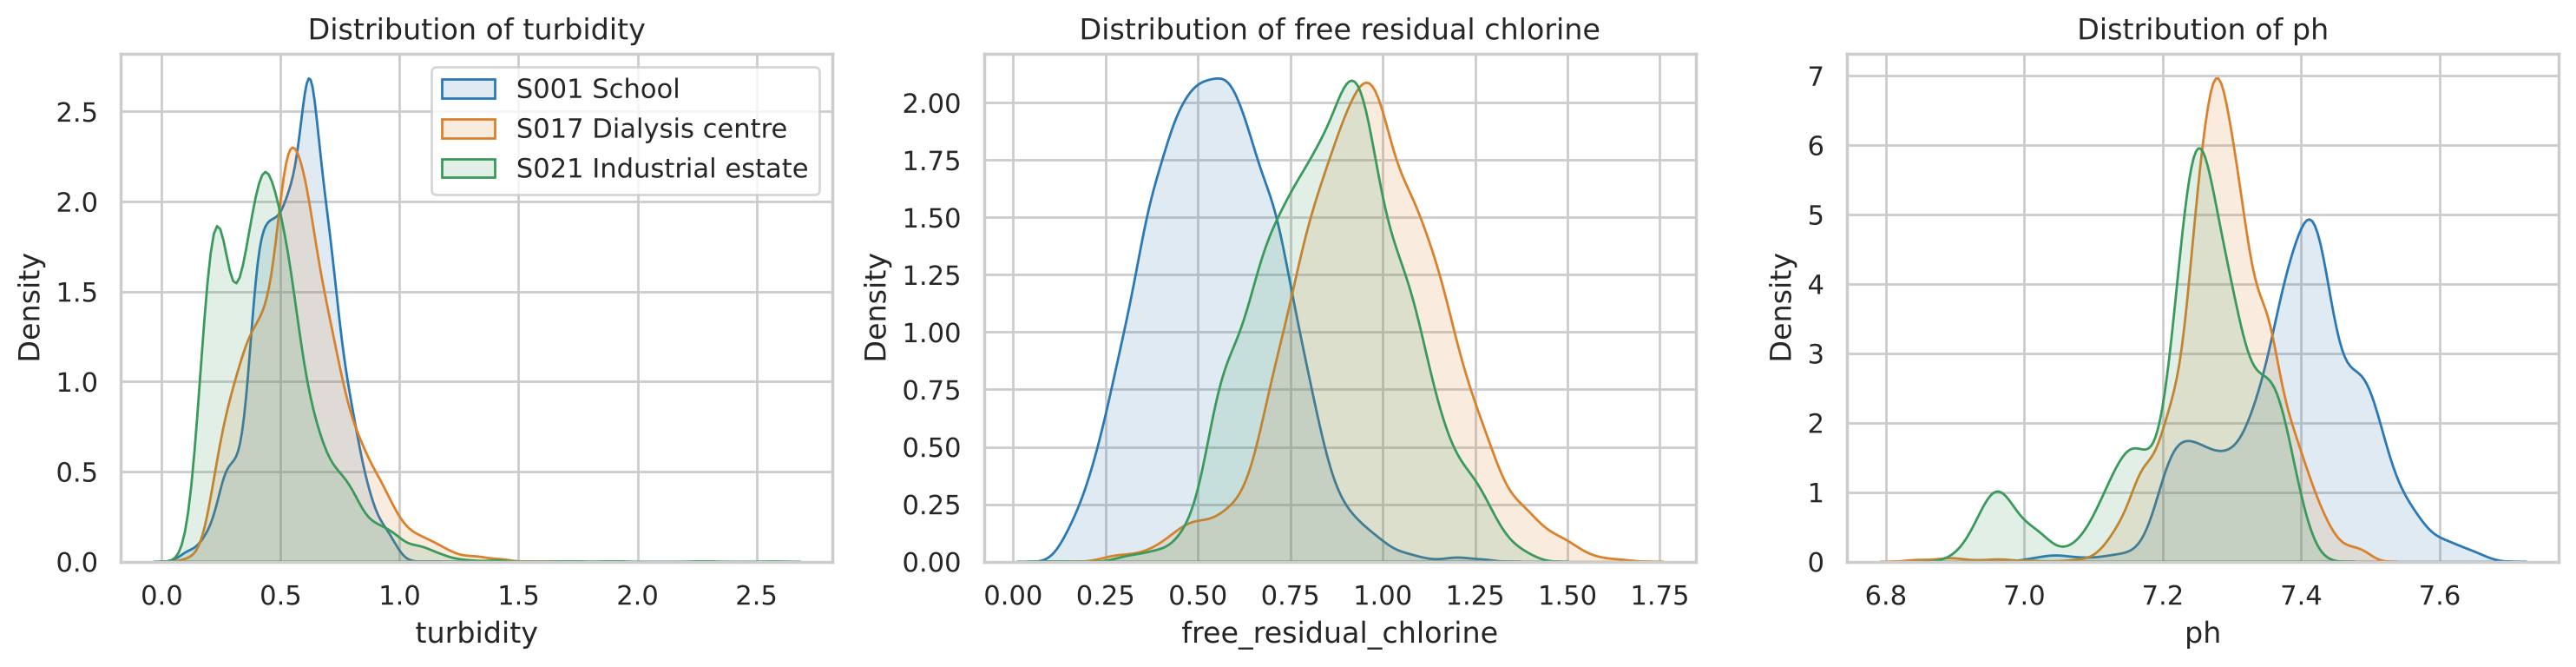

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["turbidity", "free_residual_chlorine", "ph"]):
    for s in STATIONS:
        sns.kdeplot(df.loc[df.station_code == s, col], ax=ax, label=STATION_LABEL[s],
                    color=PALETTE[s], fill=True, alpha=.15)
    ax.set_title(f"Distribution of {col.replace('_', ' ')}")
axes[0].legend()
savefig("02_distributions.png"); plt.show()

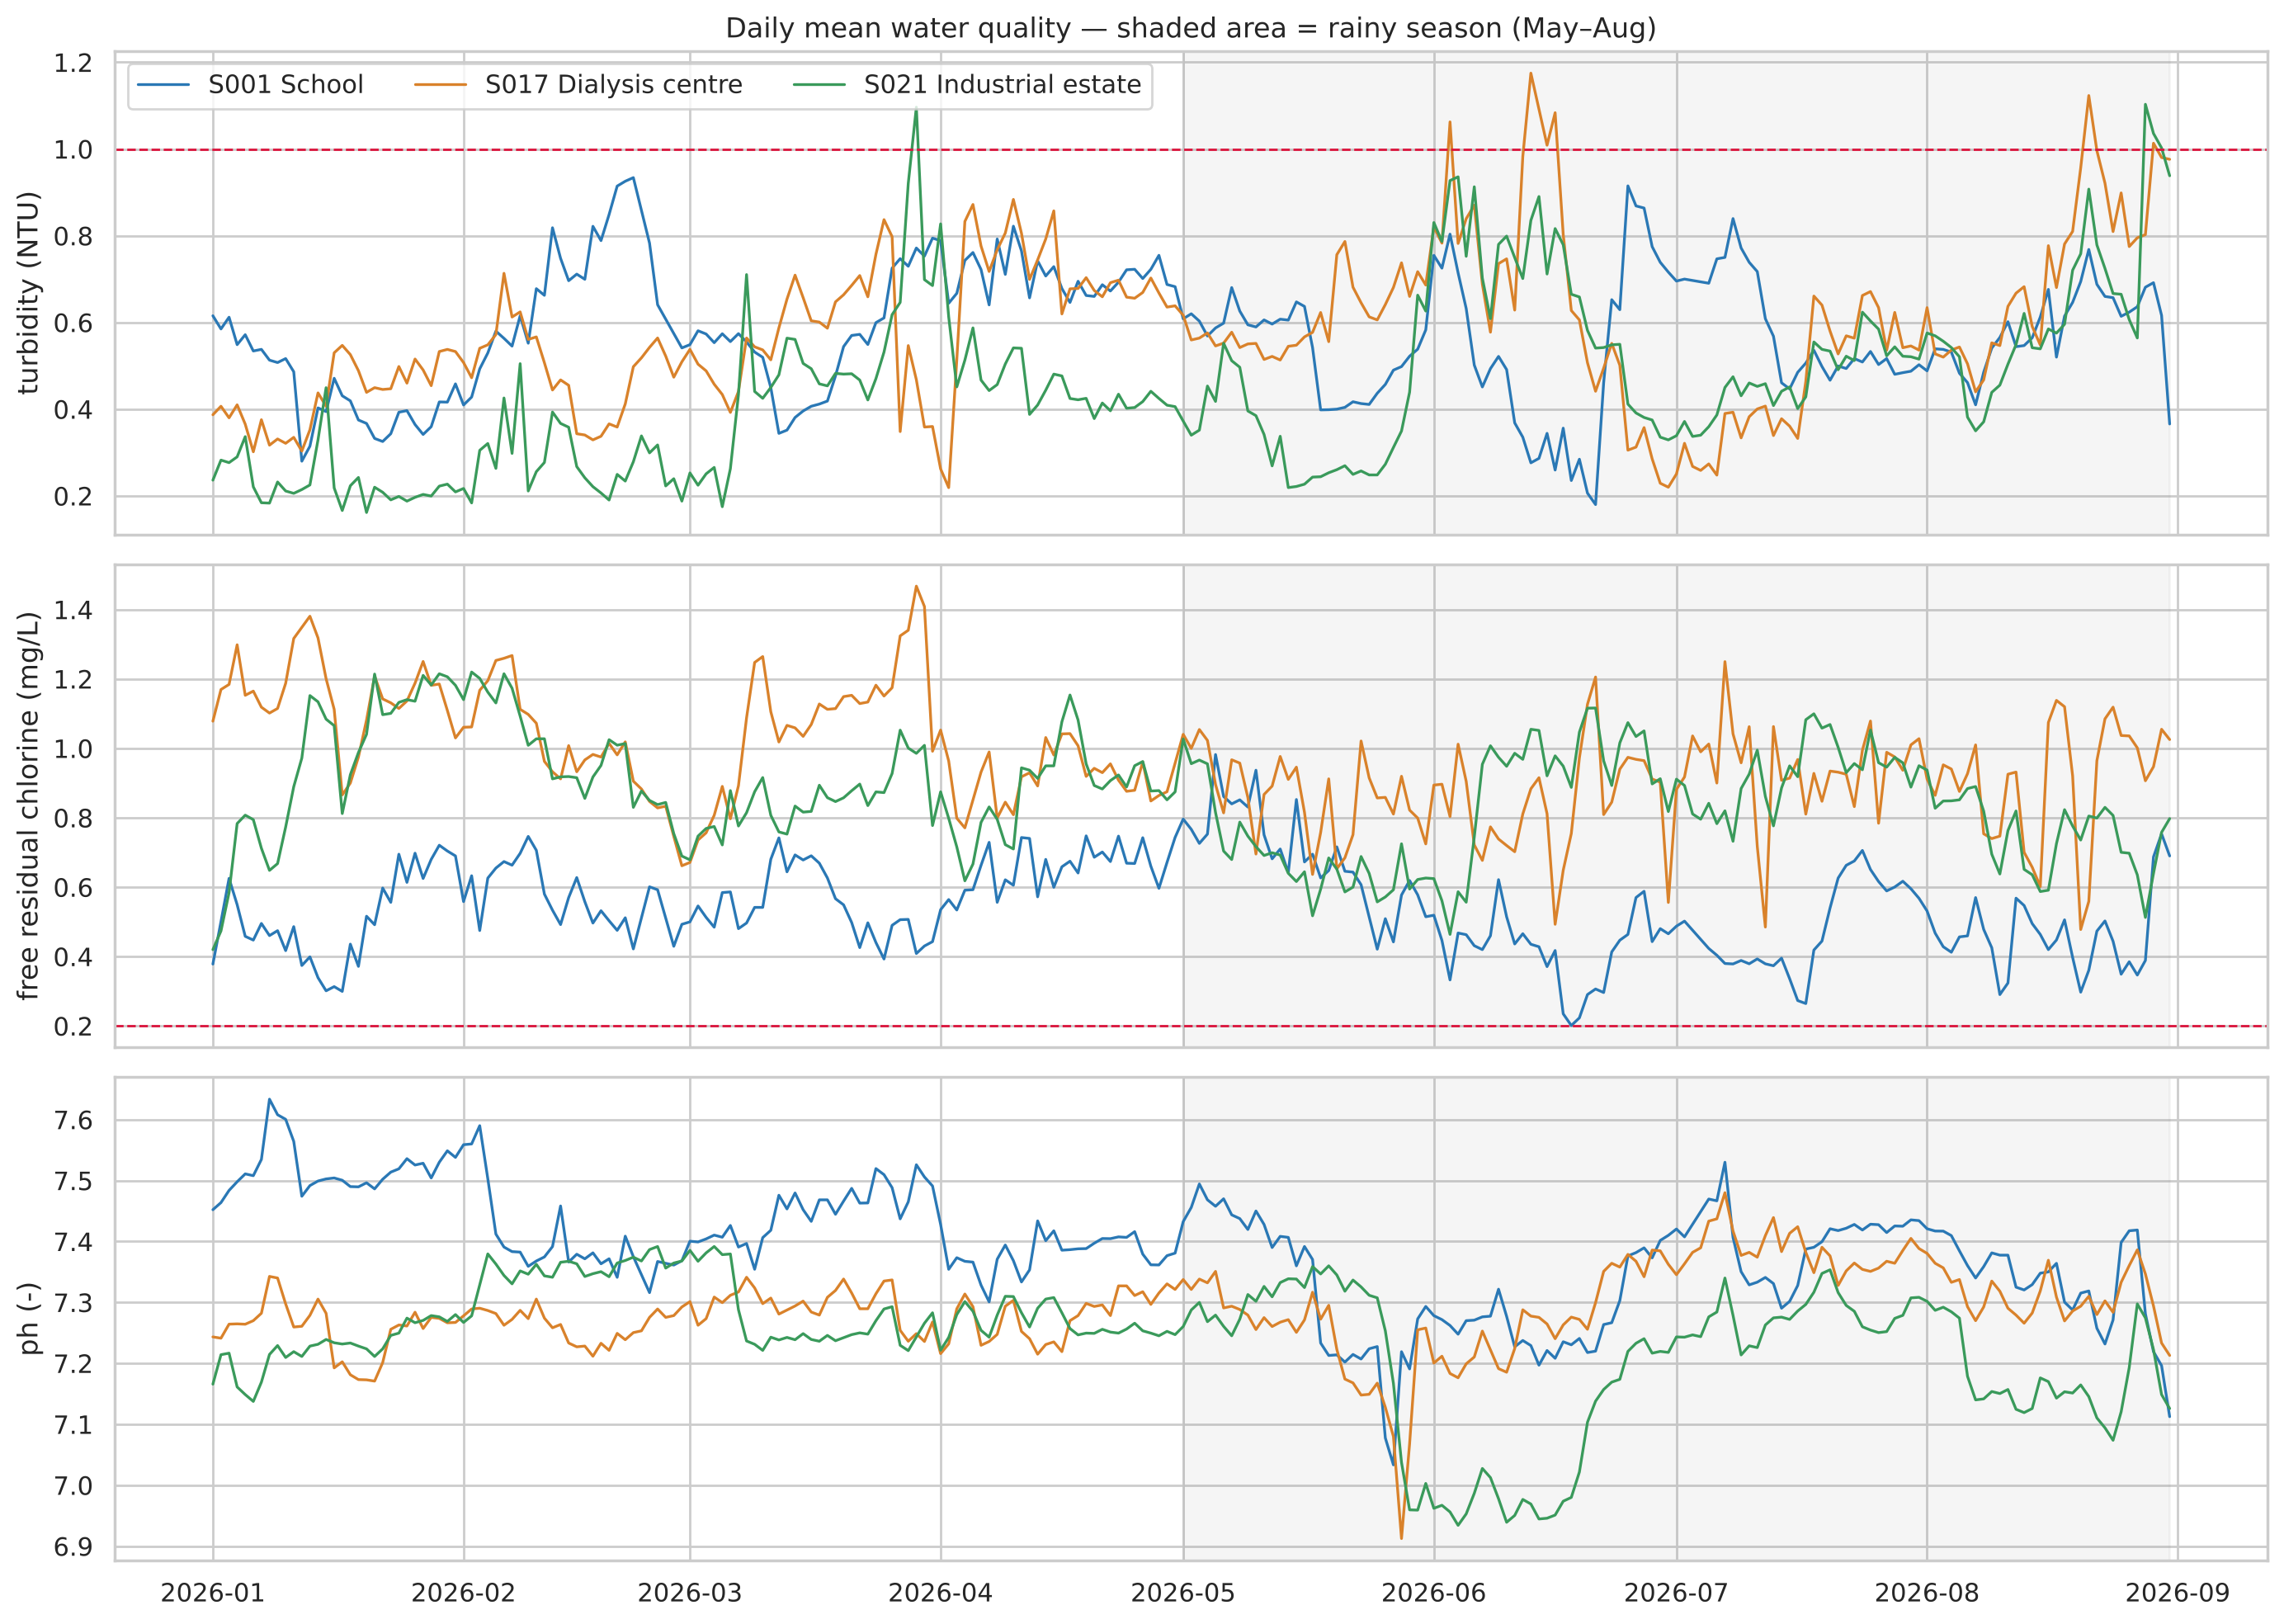

In [14]:
daily = (df.groupby(["station_code", "date"])[["turbidity", "free_residual_chlorine", "ph", "conductivity"]]
           .mean().reset_index())

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, (col, unit, ref) in zip(axes, [
        ("turbidity", "NTU", TURB_TARGET),
        ("free_residual_chlorine", "mg/L", CL_MIN),
        ("ph", "-", None)]):
    for s in STATIONS:
        d = daily[daily.station_code == s]
        ax.plot(d.date, d[col], color=PALETTE[s], lw=1.2, label=STATION_LABEL[s])
    if ref is not None:
        ax.axhline(ref, ls="--", c="crimson", lw=1)
    ax.axvspan(pd.Timestamp("2026-05-01"), pd.Timestamp("2026-08-31"), color="grey", alpha=.08)
    ax.set_ylabel(f"{col.replace('_', ' ')} ({unit})")
axes[0].legend(ncol=3, loc="upper left")
axes[0].set_title("Daily mean water quality — shaded area = rainy season (May–Aug)")
savefig("03_daily_timeseries.png"); plt.show()

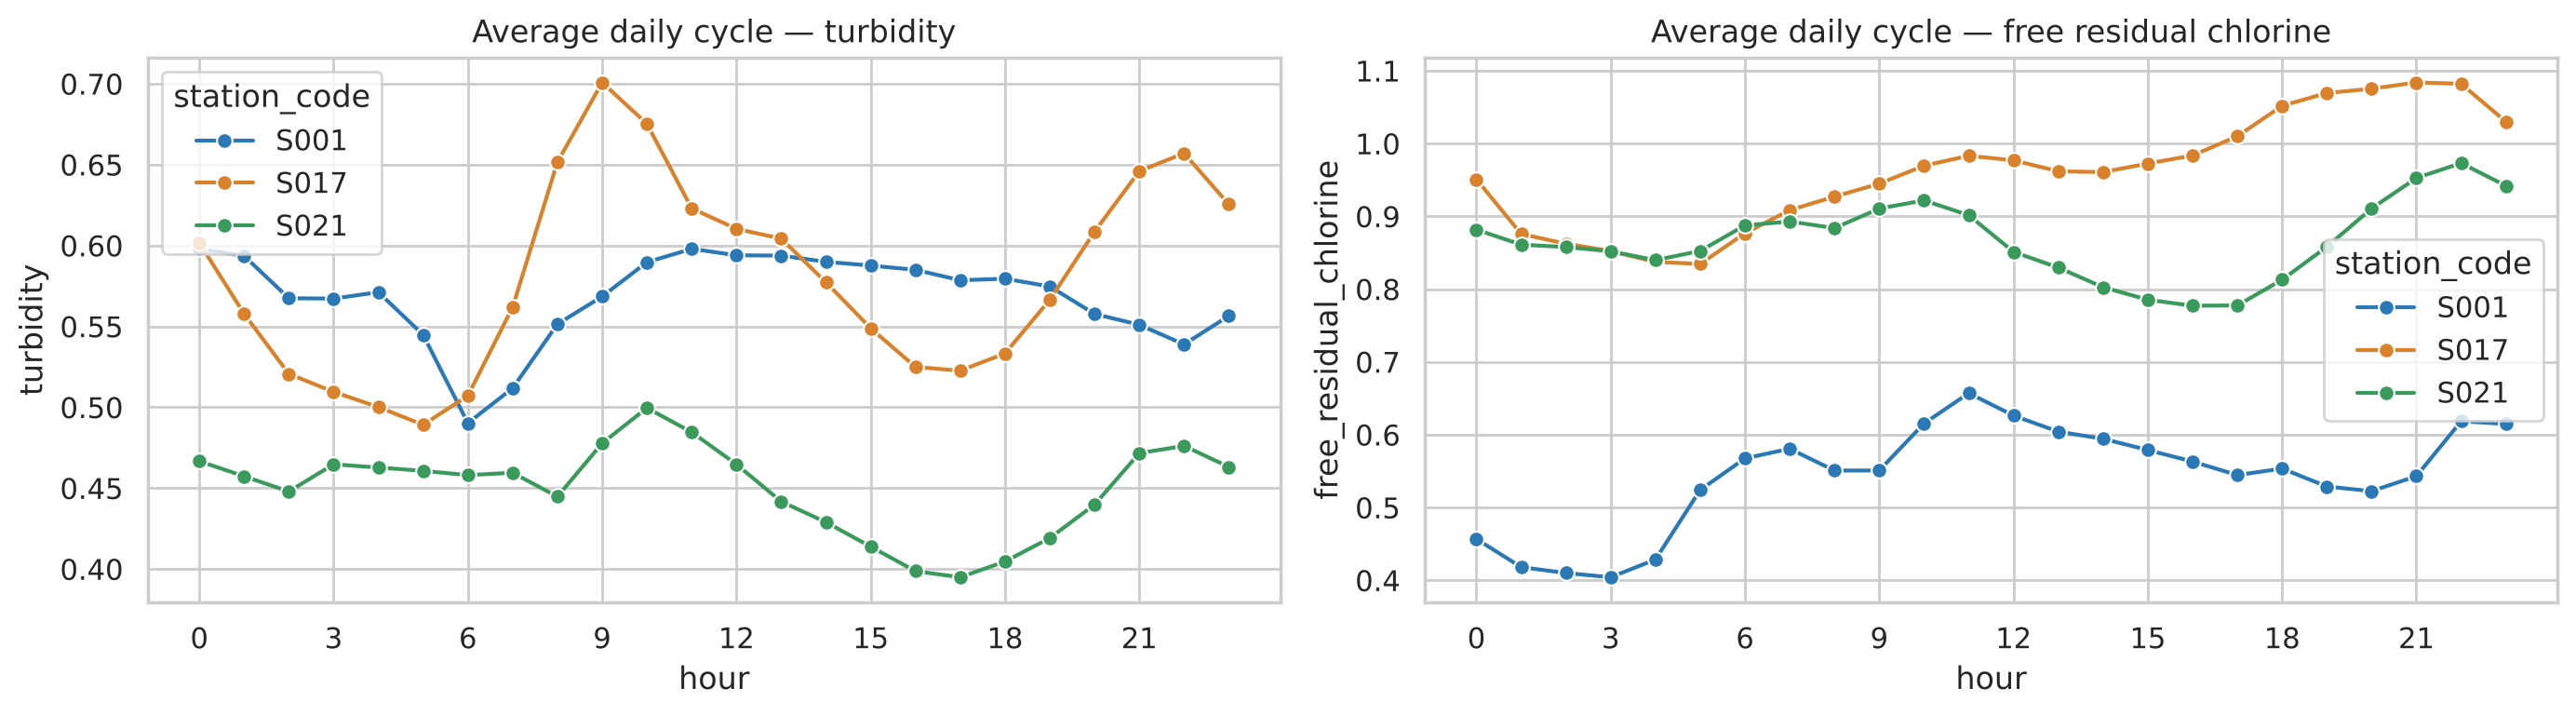

In [15]:
hourly_profile = df.groupby(["station_code", "hour"])[["turbidity", "free_residual_chlorine"]].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["turbidity", "free_residual_chlorine"]):
    sns.lineplot(data=hourly_profile, x="hour", y=col, hue="station_code", palette=PALETTE, ax=ax, marker="o")
    ax.set_title(f"Average daily cycle — {col.replace('_', ' ')}"); ax.set_xticks(range(0, 24, 3))
savefig("04_diurnal_cycle.png"); plt.show()

## 4. Data Analysis and Insights Extraction / การวิเคราะห์และสกัดข้อค้นพบ

### 4.1 Compliance with drinking-water criteria / การผ่านเกณฑ์

In [16]:
compliance = df.groupby("station_code").agg(
    hours=("turbidity", "size"),
    cl_below_0_2_pct=("free_residual_chlorine", lambda x: 100 * (x < CL_MIN).mean()),
    cl_below_0_2_hours=("free_residual_chlorine", lambda x: int((x < CL_MIN).sum())),
    turb_above_1_pct=("turbidity", lambda x: 100 * (x > TURB_TARGET).mean()),
    turb_above_5_pct=("turbidity", lambda x: 100 * (x > TURB_MAX).mean()),
    ph_out_of_range_pct=("ph", lambda x: 100 * ((x < PH_MIN) | (x > PH_MAX)).mean()),
)
compliance

,hours,cl_below_0_2_pct,cl_below_0_2_hours,turb_above_1_pct,turb_above_5_pct,ph_out_of_range_pct
station_code,,,,,,
S001,5458,1.209,66,0.073,0.000,0.000
S017,5704,0.000,0,3.471,0.000,0.000
S021,5707,0.018,1,1.840,0.000,0.000


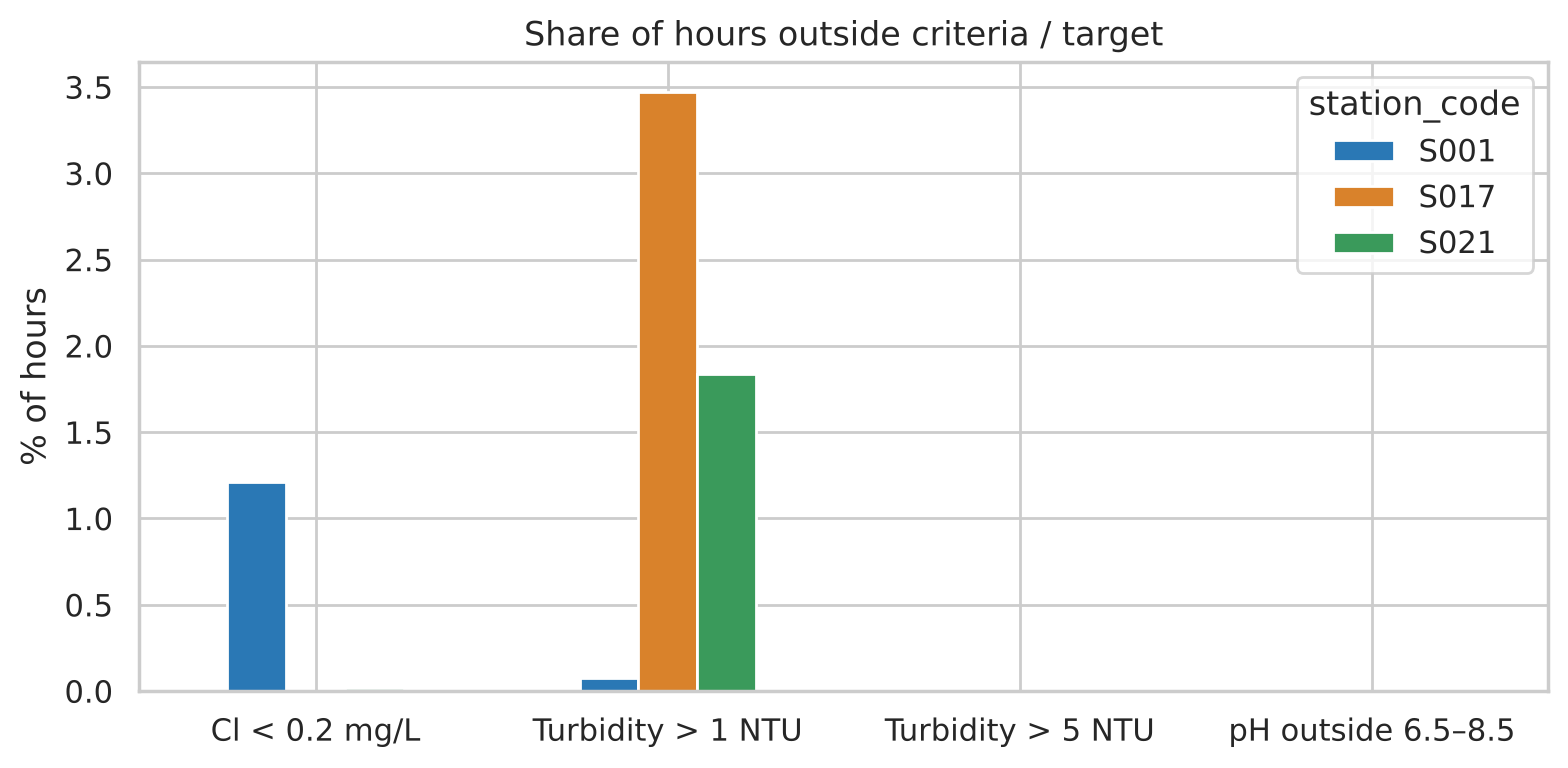

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
c = compliance[["cl_below_0_2_pct", "turb_above_1_pct", "turb_above_5_pct", "ph_out_of_range_pct"]]
c.columns = ["Cl < 0.2 mg/L", "Turbidity > 1 NTU", "Turbidity > 5 NTU", "pH outside 6.5–8.5"]
c.T.plot.bar(ax=ax, color=[PALETTE[s] for s in c.index], rot=0)
ax.set_ylabel("% of hours"); ax.set_title("Share of hours outside criteria / target")
savefig("05_compliance.png"); plt.show()

### 4.2 Monthly pattern and dry vs. rainy season / รายเดือนและเปรียบเทียบฤดู

In [18]:
monthly = df.groupby(["station_code", "month"])[["turbidity", "free_residual_chlorine", "ph"]].mean().unstack(0)
monthly.round(3)

turbidity             free_residual_chlorine                ph  \
station_code      S001  S017  S021                   S001  S017  S021  S001   
month                                                                         
1                0.440 0.430 0.231                  0.507 1.153 0.953 7.517   
2                0.654 0.489 0.281                  0.578 0.997 0.982 7.409   
3                0.553 0.567 0.507                  0.544 1.079 0.851 7.448   
4                0.708 0.691 0.462                  0.655 0.920 0.880 7.381   
5                0.539 0.606 0.347                  0.694 0.866 0.696 7.330   
6                0.518 0.667 0.658                  0.416 0.844 0.908 7.276   
7                0.571 0.455 0.471                  0.490 0.929 0.928 7.396   
8                0.588 0.735 0.645                  0.460 0.899 0.749 7.332   

                          
station_code  S017  S021  
month                     
1            7.254 7.226  
2            7.264 7.352  
3            7.295 7.271  
4            7.277 7.266  
5            7.237 7.263  
6            7.277 7.052  
7            7.383 7.275  
8            7.310 7.178

In [19]:
season_tbl = daily.assign(season=np.where(daily.date.dt.month <= 4, "Dry", "Rainy"))
rows = []
for s in STATIONS:
    for col in ["turbidity", "free_residual_chlorine", "ph"]:
        d = season_tbl[(season_tbl.station_code == s)]
        dry, wet = d.loc[d.season == "Dry", col].dropna(), d.loc[d.season == "Rainy", col].dropna()
        u, p = stats.mannwhitneyu(dry, wet, alternative="two-sided")
        rows.append({"station": s, "parameter": col, "dry_mean": dry.mean(), "rainy_mean": wet.mean(),
                     "change_%": 100 * (wet.mean() - dry.mean()) / dry.mean(), "p_value": p})
season_cmp = pd.DataFrame(rows)
season_cmp["significant (p<0.05)"] = season_cmp.p_value < 0.05
season_cmp

,station,parameter,dry_mean,rainy_mean,change_%,p_value,significant (p<0.05)
0,S001,turbidity,0.590,0.557,-5.613,0.085,False
1,S001,free_residual_chlorine,0.568,0.517,-9.069,0.001,True
2,S001,ph,7.440,7.334,-1.425,0.000,True
3,S017,turbidity,0.544,0.614,12.894,0.006,True
4,S017,free_residual_chlorine,1.039,0.889,-14.509,0.000,True
5,S017,ph,7.273,7.302,0.397,0.000,True
6,S021,turbidity,0.370,0.528,42.848,0.000,True
7,S021,free_residual_chlorine,0.914,0.819,-10.450,0.000,True
8,S021,ph,7.278,7.193,-1.165,0.000,True


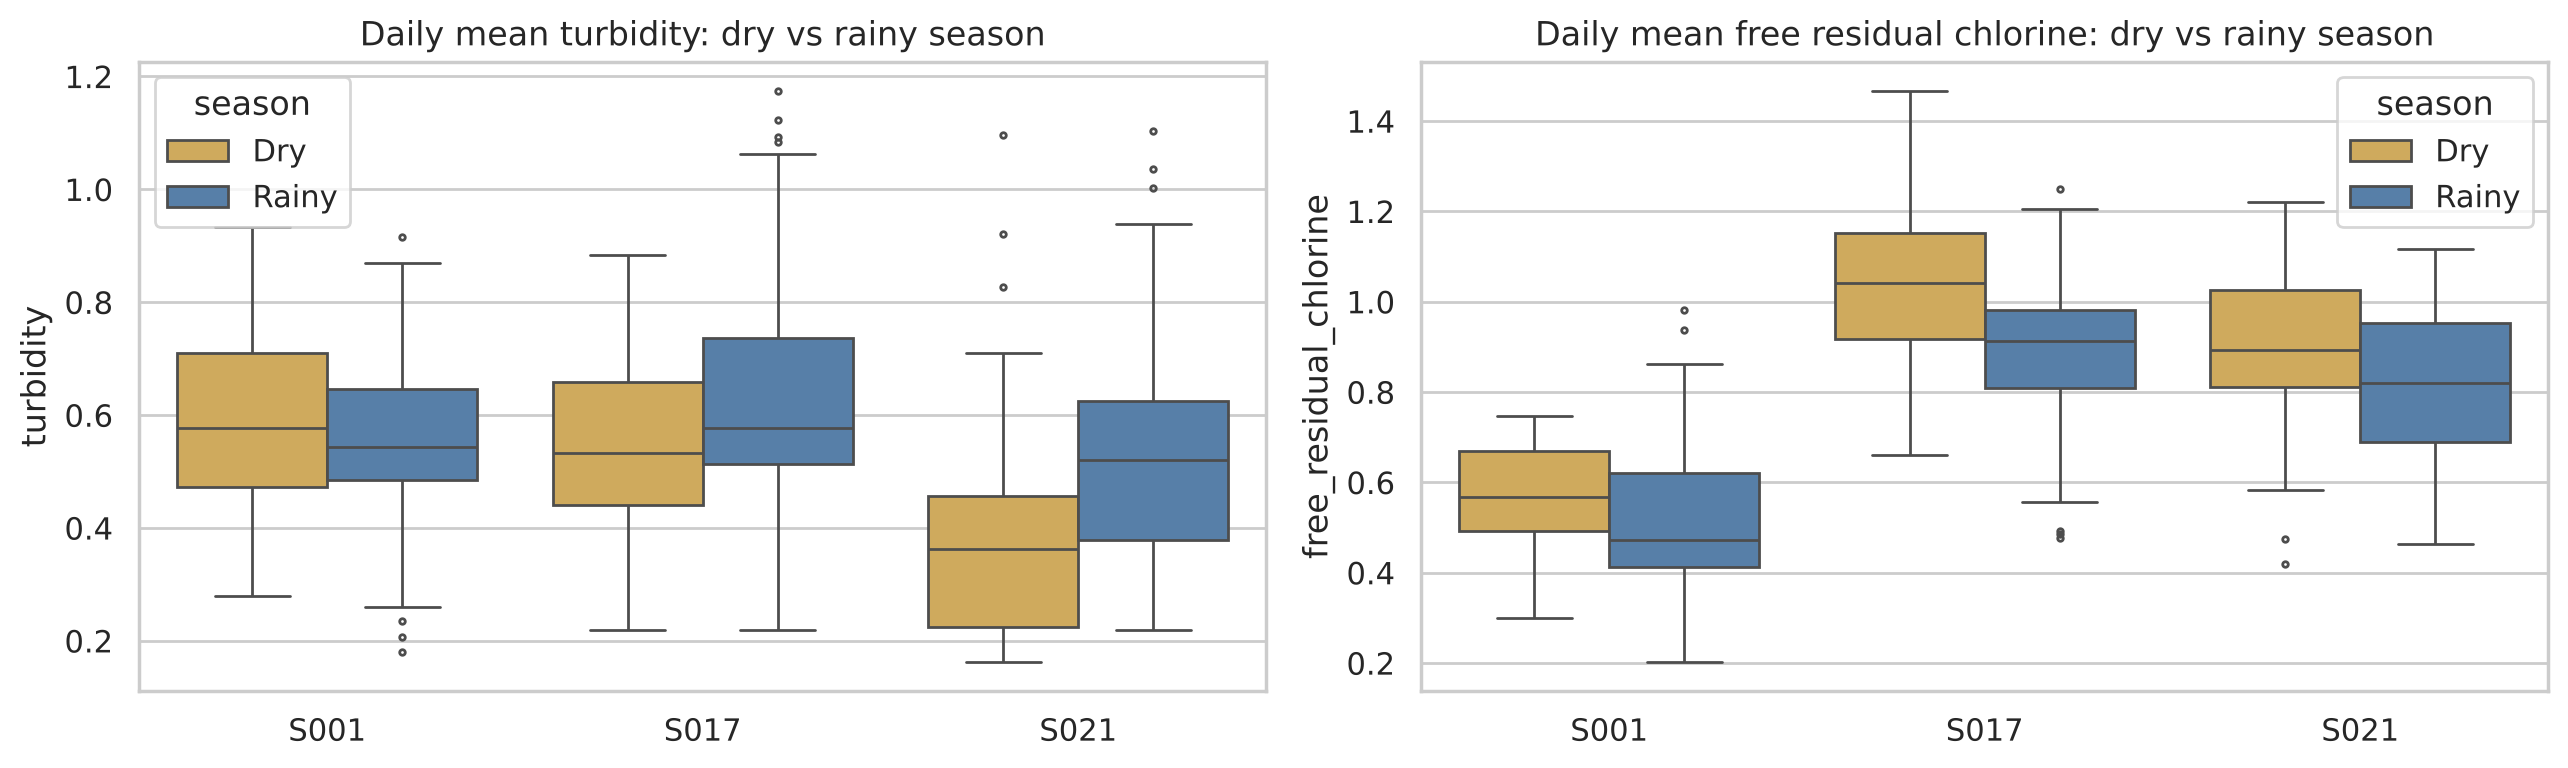

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["turbidity", "free_residual_chlorine"]):
    sns.boxplot(data=season_tbl, x="station_code", y=col, hue="season", order=STATIONS,
                palette={"Dry": "#e2b04a", "Rainy": "#4a7fb5"}, ax=ax, fliersize=2)
    ax.set_title(f"Daily mean {col.replace('_', ' ')}: dry vs rainy season"); ax.set_xlabel("")
savefig("06_season_comparison.png"); plt.show()

*Mann–Whitney U test on daily means (non-parametric; daily values are autocorrelated, so p-values are indicative rather than exact).*

*ใช้ Mann–Whitney U กับค่าเฉลี่ยรายวัน (ข้อมูลรายวันมีความสัมพันธ์ต่อเนื่องกัน ค่า p จึงใช้เป็นแนวทาง ไม่ใช่ค่าที่แม่นยำ)*

### 4.3 Relationships between parameters / ความสัมพันธ์ระหว่างพารามิเตอร์

In [21]:
pairs = [("turbidity", "ph"), ("turbidity", "free_residual_chlorine"), ("free_residual_chlorine", "ph"),
         ("conductivity", "free_residual_chlorine")]
corr_rows = []
for s in STATIONS:
    d = daily[daily.station_code == s]
    for a, b in pairs:
        r, p = stats.pearsonr(d[a], d[b])
        corr_rows.append({"station": s, "pair": f"{a} vs {b}", "pearson_r": r, "p_value": p})
corr = pd.DataFrame(corr_rows).pivot(index="pair", columns="station", values="pearson_r")
corr

station,S001,S017,S021
pair,,,
conductivity vs free_residual_chlorine,-0.569,-0.011,0.017
free_residual_chlorine vs ph,0.157,0.021,0.131
turbidity vs free_residual_chlorine,0.095,-0.271,-0.139
turbidity vs ph,0.041,-0.244,-0.588


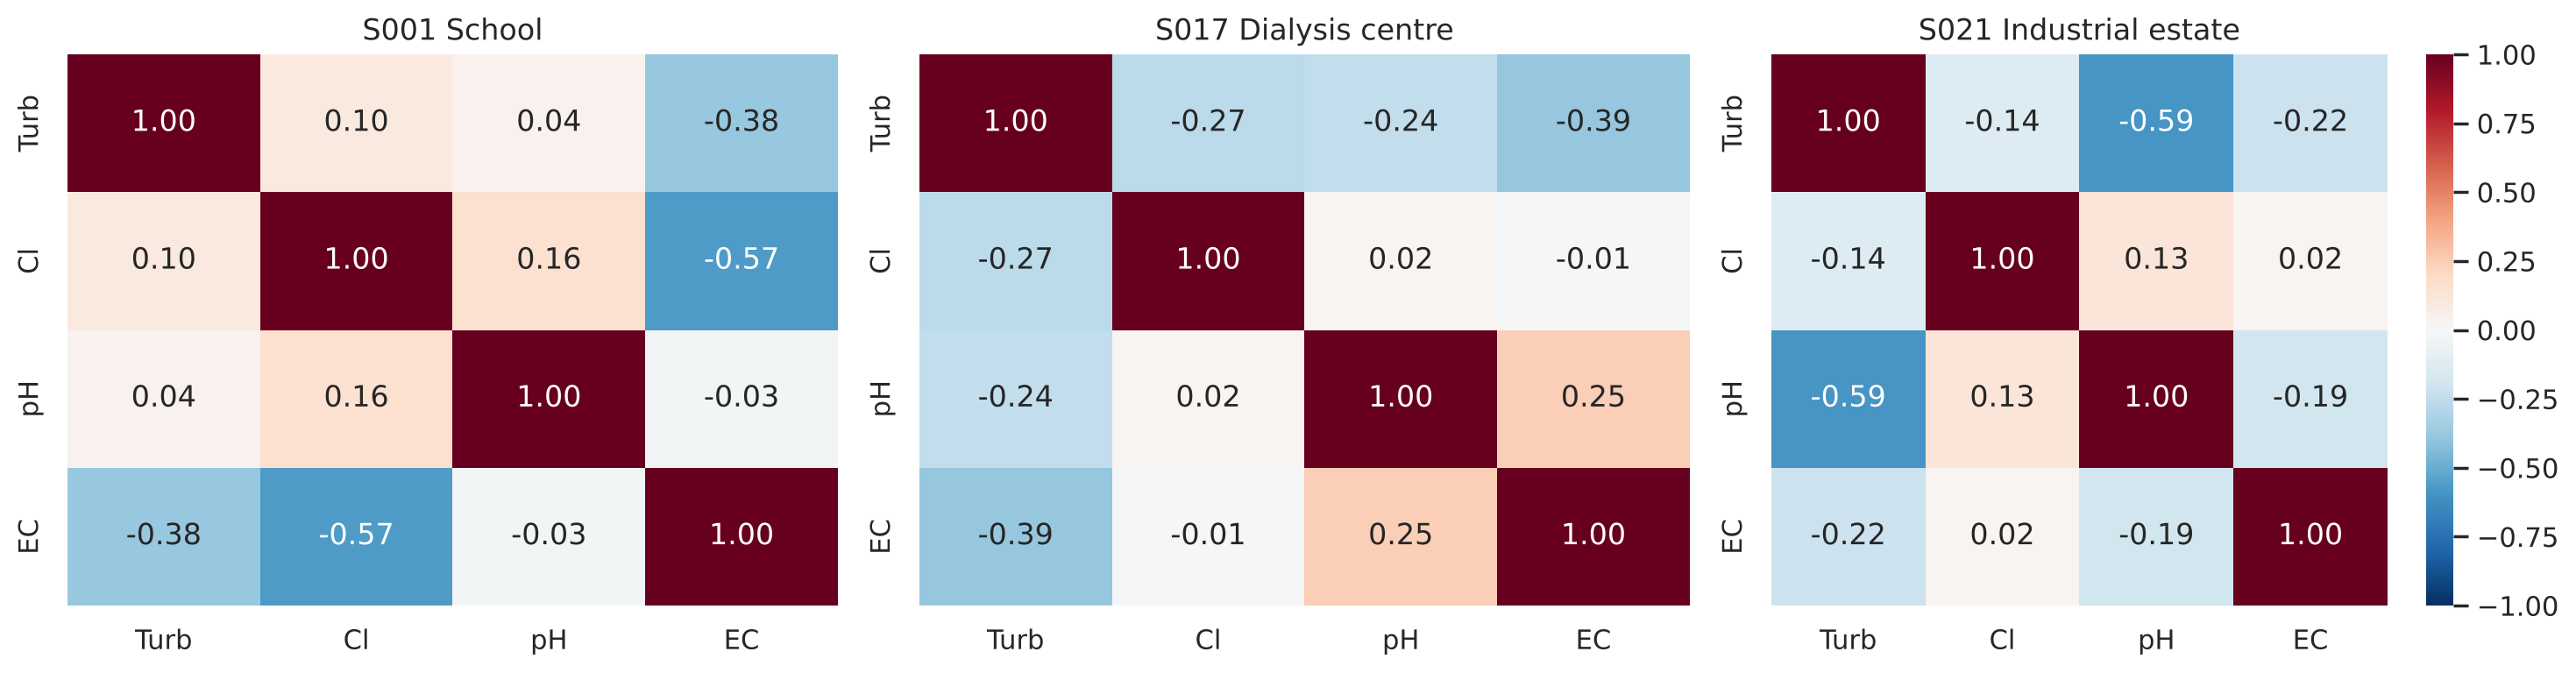

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cols = ["turbidity", "free_residual_chlorine", "ph", "conductivity"]
short = ["Turb", "Cl", "pH", "EC"]
for ax, s in zip(axes, STATIONS):
    m = daily[daily.station_code == s][cols].corr()
    m.index = m.columns = short
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=s == "S021")
    ax.set_title(STATION_LABEL[s])
savefig("07_correlation_heatmaps.png"); plt.show()

## 5. Basic Machine Learning: next-hour chlorine forecast / การทำนายคลอรีนชั่วโมงถัดไป

**Goal / เป้าหมาย:** predict free residual chlorine **1 hour ahead** so operators get an early warning before it drops toward 0.2 mg/L.

**Set-up / การออกแบบ**
- Target: chlorine at hour *t+1* / ค่าคลอรีนชั่วโมงถัดไป
- Time-based split: train Jan–Jun, test Jul–Aug (no shuffling, to avoid leaking the future) / แบ่งตามเวลา
- Models: persistence baseline (next hour = this hour), Linear Regression, Random Forest
- Two feature sets: **A** = other parameters + time only (no chlorine history); **B** = A + chlorine lags (1, 2, 3, 24 h) and 6-h rolling mean

In [23]:
def make_features(g):
    g = g.set_index("date_time").asfreq("h")          # put gaps back so lags don't jump across them
    g["station_code"] = g["station_code"].ffill().bfill()
    cl = g["free_residual_chlorine"]
    g["target_cl_t+1"] = cl.shift(-1)
    g["cl_lag1"] = cl                                   # value at t (latest known)
    g["cl_lag2"] = cl.shift(1)
    g["cl_lag3"] = cl.shift(2)
    g["cl_lag24"] = cl.shift(23)
    g["cl_roll6"] = cl.rolling(6, min_periods=4).mean()
    g["turb_roll6"] = g["turbidity"].rolling(6, min_periods=4).mean()
    g["hour"] = g.index.hour
    g["month"] = g.index.month
    return g.reset_index()

feat = pd.concat([make_features(g) for _, g in df.groupby("station_code")], ignore_index=True)
feat = pd.get_dummies(feat, columns=["station_code"], prefix="st", dtype=int)

F_A = ["turbidity", "turb_roll6", "ph", "conductivity", "salinity", "hour", "month",
       "st_S001", "st_S017", "st_S021"]
F_B = F_A + ["cl_lag1", "cl_lag2", "cl_lag3", "cl_lag24", "cl_roll6"]
TARGET = "target_cl_t+1"

model_df = feat.dropna(subset=F_B + [TARGET])
train = model_df[model_df.date_time < "2026-07-01"]
test = model_df[model_df.date_time >= "2026-07-01"]
print(f"Train rows: {len(train):,}   Test rows: {len(test):,}")

Train rows: 11,831   Test rows: 3,949


In [24]:
def score(name, y, p):
    return {"model": name, "MAE": mean_absolute_error(y, p),
            "RMSE": mean_squared_error(y, p) ** 0.5, "R2": r2_score(y, p)}

results, preds = [], {}
y_te = test[TARGET]

preds["Persistence"] = test["cl_lag1"]
results.append(score("Persistence baseline (Cl_t+1 = Cl_t)", y_te, preds["Persistence"]))

for label, F in [("A", F_A), ("B", F_B)]:
    lr = LinearRegression().fit(train[F], train[TARGET])
    preds[f"LR-{label}"] = lr.predict(test[F])
    results.append(score(f"Linear Regression — features {label}", y_te, preds[f"LR-{label}"]))

    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42)
    rf.fit(train[F], train[TARGET])
    preds[f"RF-{label}"] = rf.predict(test[F])
    results.append(score(f"Random Forest — features {label}", y_te, preds[f"RF-{label}"]))
    if label == "B":
        rf_B = rf

results = pd.DataFrame(results).set_index("model")
results

,MAE,RMSE,R2
model,,,
Persistence baseline (Cl_t+1 = Cl_t),0.040,0.060,0.945
Linear Regression — features A,0.151,0.186,0.469
Random Forest — features A,0.151,0.188,0.456
Linear Regression — features B,0.037,0.056,0.952
Random Forest — features B,0.033,0.050,0.961


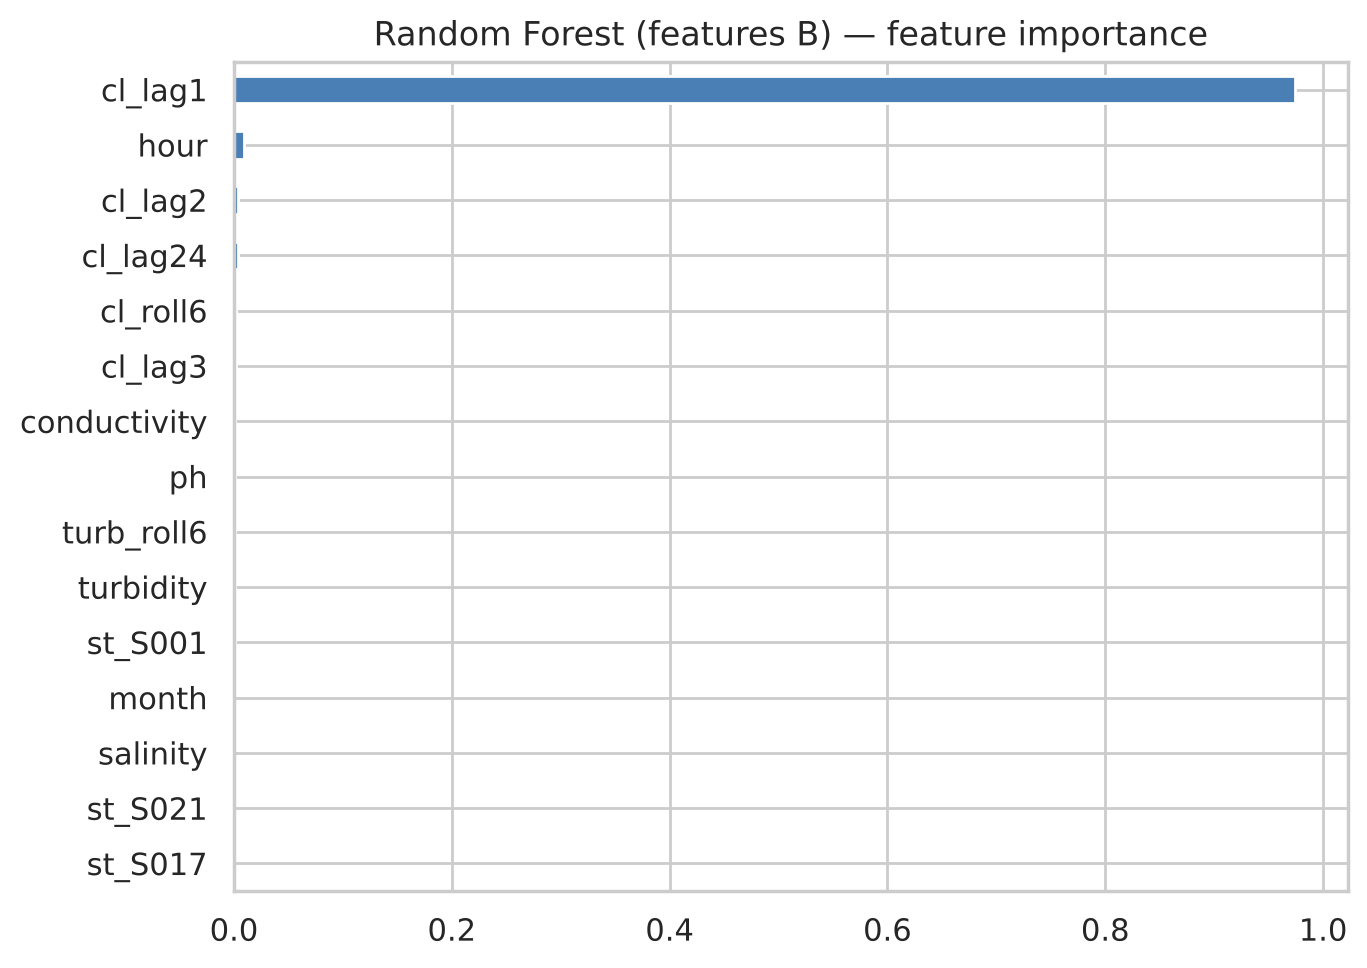

In [25]:
imp = pd.Series(rf_B.feature_importances_, index=F_B).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
imp.plot.barh(ax=ax, color="#4a7fb5")
ax.set_title("Random Forest (features B) — feature importance")
savefig("08_feature_importance.png"); plt.show()

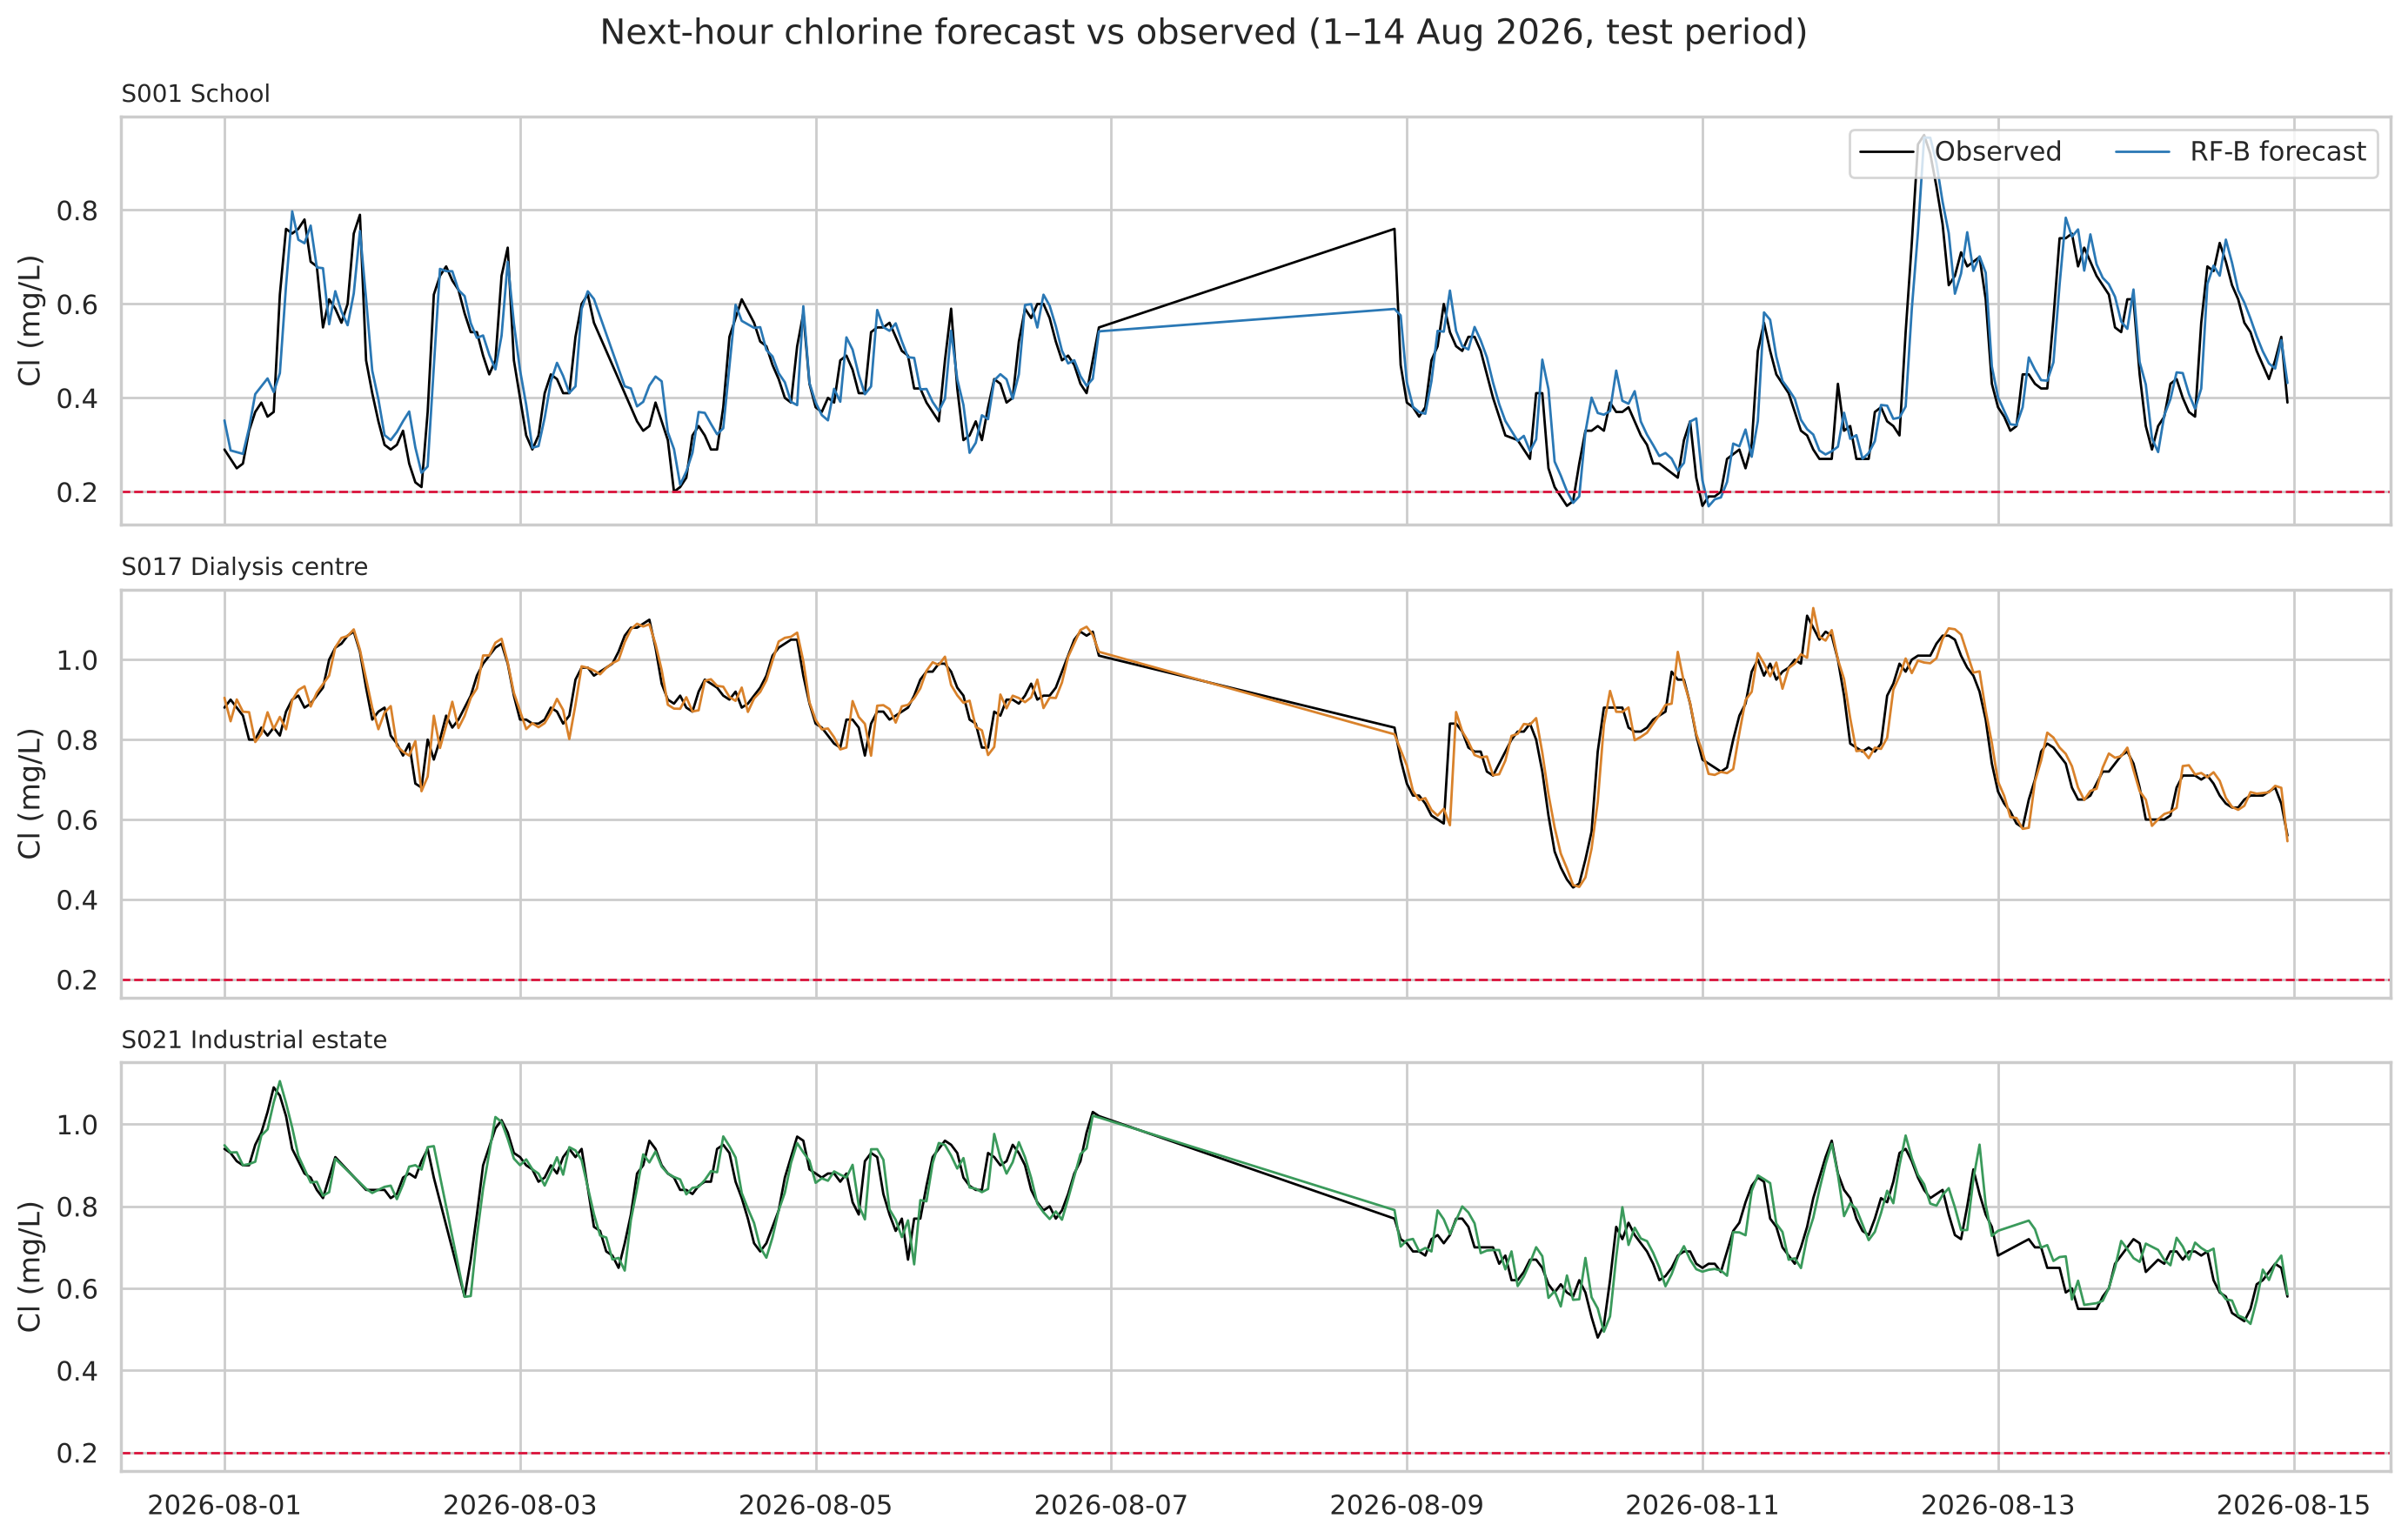

In [26]:
fig, axes = plt.subplots(len(STATIONS), 1, figsize=(14, 9), sharex=True)
window = (test.date_time >= "2026-08-01") & (test.date_time < "2026-08-15")
for ax, s in zip(axes, STATIONS):
    m = window & (test[f"st_{s}"] == 1)
    ax.plot(test.loc[m, "date_time"], y_te[m], c="black", lw=1, label="Observed")
    ax.plot(test.loc[m, "date_time"], preds["RF-B"][m.values], c=PALETTE[s], lw=1, label="RF-B forecast")
    ax.axhline(CL_MIN, ls="--", c="crimson", lw=1)
    ax.set_ylabel("Cl (mg/L)"); ax.set_title(STATION_LABEL[s], loc="left", fontsize=10)
axes[0].legend(ncol=2, loc="upper right")
fig.suptitle("Next-hour chlorine forecast vs observed (1–14 Aug 2026, test period)")
savefig("09_forecast_vs_observed.png"); plt.show()

In [27]:
# Early-warning check: can the model flag hours where chlorine will fall below a 0.3 mg/L alert level?
ALERT = 0.3
actual_alert = y_te < ALERT
for name in ["Persistence", "RF-B"]:
    p = np.asarray(preds[name]) < ALERT
    tp = (p & actual_alert.values).sum(); fn = (~p & actual_alert.values).sum(); fp = (p & ~actual_alert.values).sum()
    rec = tp / (tp + fn) if tp + fn else np.nan; prec = tp / (tp + fp) if tp + fp else np.nan
    print(f"{name:12s} actual alert hours={actual_alert.sum():4d}  recall={rec:.2f}  precision={prec:.2f}")

Persistence  actual alert hours= 167  recall=0.74  precision=0.73
RF-B         actual alert hours= 167  recall=0.77  precision=0.82


## 6. Environmental Interpretation / การตีความเชิงสิ่งแวดล้อม

See the README for the full bilingual write-up. Key points / ประเด็นหลัก:

- **Chlorine decay in the network / การสลายตัวของคลอรีนในท่อ** — S001 has clearly lower chlorine than S017 and S021, consistent with longer water age (further from the pumping station). It is the station to watch for the 0.2 mg/L minimum.
- **Rainy-season raw water / น้ำดิบฤดูฝน** — turbidity rises in the rainy season (most at S021) while chlorine falls: more suspended and organic matter exerts chlorine demand, and warmer water speeds decay.
- **pH is stable / pH คงที่** — every hour stays within 6.5–8.5; pH is not a concern for this period.
- **Conductivity at S001 / ค่าการนำไฟฟ้าที่ S001** — daily chlorine at S001 falls when conductivity rises (r ≈ −0.57), hinting that changes in source water or blending affect chlorine there; the other stations show no such link.
- **ML / แบบจำลอง** — water-quality parameters alone predict chlorine poorly (R² ≈ 0.46, mostly from knowing the station); chlorine's own recent history carries most of the signal. Random Forest with lags (R² ≈ 0.96, MAE ≈ 0.033 mg/L) beats the "same as last hour" baseline (MAE ≈ 0.040) and flags low-chlorine hours more precisely, but the gain is modest — longer horizons and external data (rainfall, water temperature, demand, dosing) are needed for a real early-warning system.
- **Limitations / ข้อจำกัด** — 3 of ~59 stations, 8 months of one year, gaps at S001, chloride unusable, correlation ≠ causation.